# Medical Insurance Charges Analysis

## Goal
Explore which customer characteristics are associated with medical insurance charges.

## Audience and purpose
This analysis is for people interested in understanding patterns in insurance costs. It may help guide further investigation, but it is not intended to set individual premiums.

## Questions
- How are charges related to smoking, age, and BMI?
- Do charges differ by sex, region, or number of children?
- Does the relationship between BMI and charges differ for smokers and non-smokers?

This is an observational analysis, so associations do not prove cause and effect.

### 1 - Load Requirments

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2 - Inspect Data

In [2]:
df = pd.read_csv("C:/Users/abdel/Desktop/ML roadmap/Medical-Insurance/Data/insurance.csv")

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### 3 - Clean The Data

In [6]:
null_values = df.isnull().sum().sum()
print("Number of null values : ", null_values)

Number of null values :  0


- So there is No null values in this data. 

In [7]:
df.columns.tolist()

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

In [8]:
Columns = ['sex', 'region', 'children']

In [9]:
for x in Columns:
    print(df[x].unique().tolist())

['female', 'male']
['southwest', 'southeast', 'northwest', 'northeast']
[0, 1, 3, 2, 5, 4]


- So there is no grammer erros all records are same. 

In [10]:
print("There Number of Duplicates rows is",df.duplicated().sum(), "Duplicate Row")

There Number of Duplicates rows is 1 Duplicate Row


In [11]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [12]:
df = df.drop_duplicates().reset_index(drop=True)

In [13]:
df.duplicated().any()

np.False_

- So Duplicate Rows Problem Fixed.

### Overall Charges

* Review summary statistics and the distribution of insurance charges.

In [14]:
df['charges'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])

count      1337.000000
mean      13279.121487
median     9386.161300
std       12110.359656
min        1121.873900
max       63770.428010
Name: charges, dtype: float64

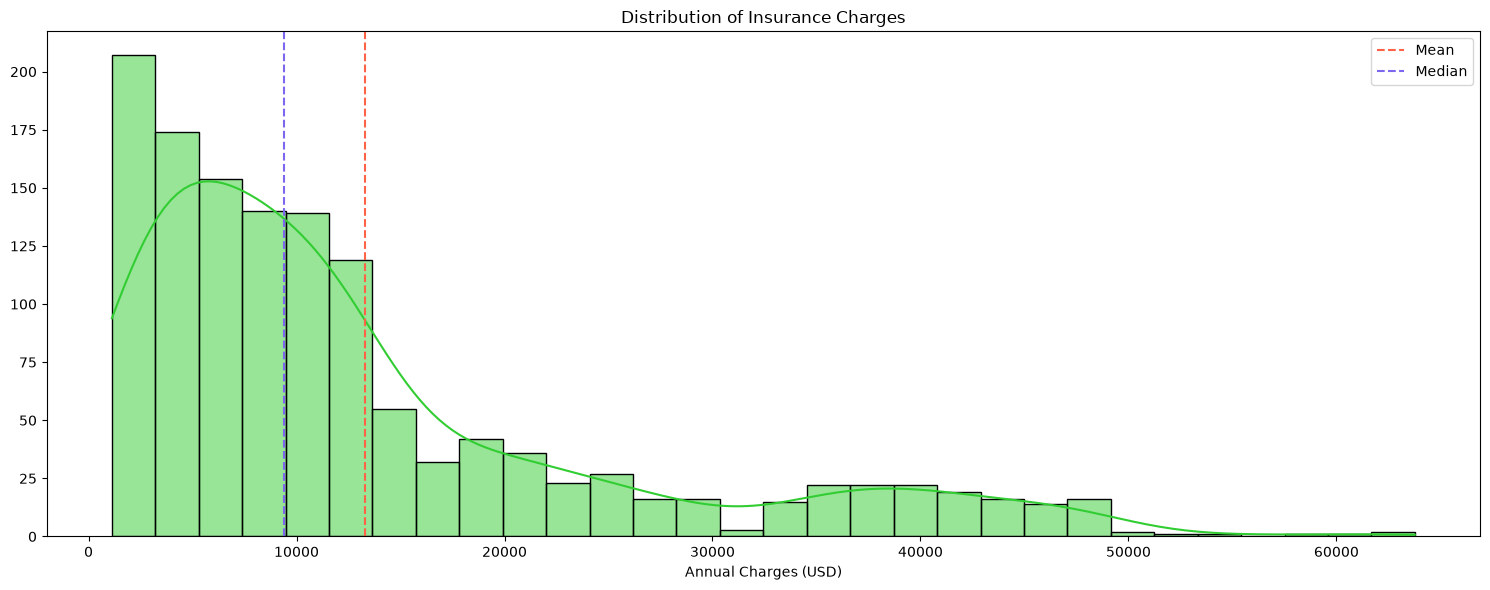

In [15]:
plt.figure(figsize=(15, 6))
sns.histplot(data=df, x='charges', bins=30, kde=True, color="limegreen")
plt.axvline(df['charges'].mean(), color='tomato', linestyle='--', label='Mean')
plt.axvline(df['charges'].median(), color='mediumslateblue', linestyle='--', label='Median')
plt.title('Distribution of Insurance Charges')
plt.xlabel('Annual Charges (USD)')
plt.ylabel('')
plt.legend()
plt.tight_layout()
plt.show()

### 4 - relationships

In [16]:
cols = ['age', 'bmi', 'children', 'charges']

corr = df[cols].corr()

corr

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


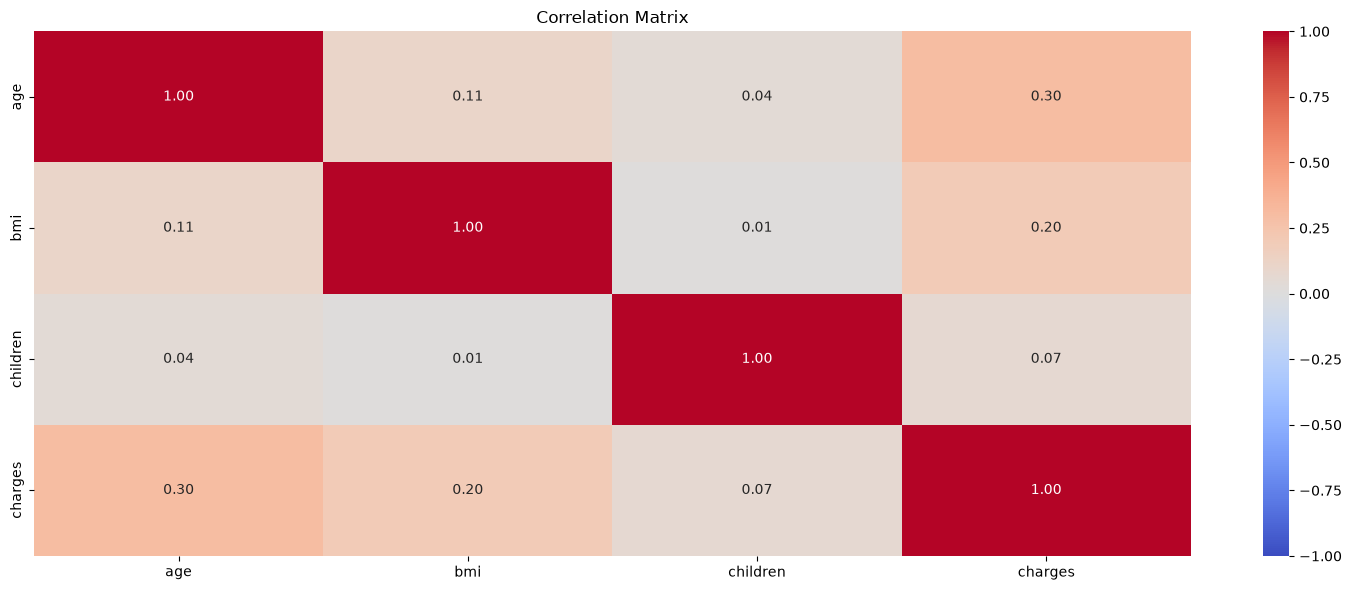

In [17]:
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation Matrix')
plt.tight_layout()
plt.show()

- **Numirical Features** Doesn't effect the **``charges``** to much .
- Among the **numerical features** examined, ``age`` has the **strongest positive correlation** with insurance charges ``(r = 0.30)``
- While ``BMI`` has a weaker **positive** correlation ``(r = 0.20).``
- The ``number of children`` shows little **linear association** with ``charges`` ``(r = 0.07)``.
- These **results** describe correlations, not causation, and do not account for other factors that may **influence charges**.

### Now We test the non Numirical ones.

#### Charges by sex Status

C:\Users\abdel\AppData\Local\Temp\ipykernel_7696\3231123618.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='charges', y='sex', palette='Set2')


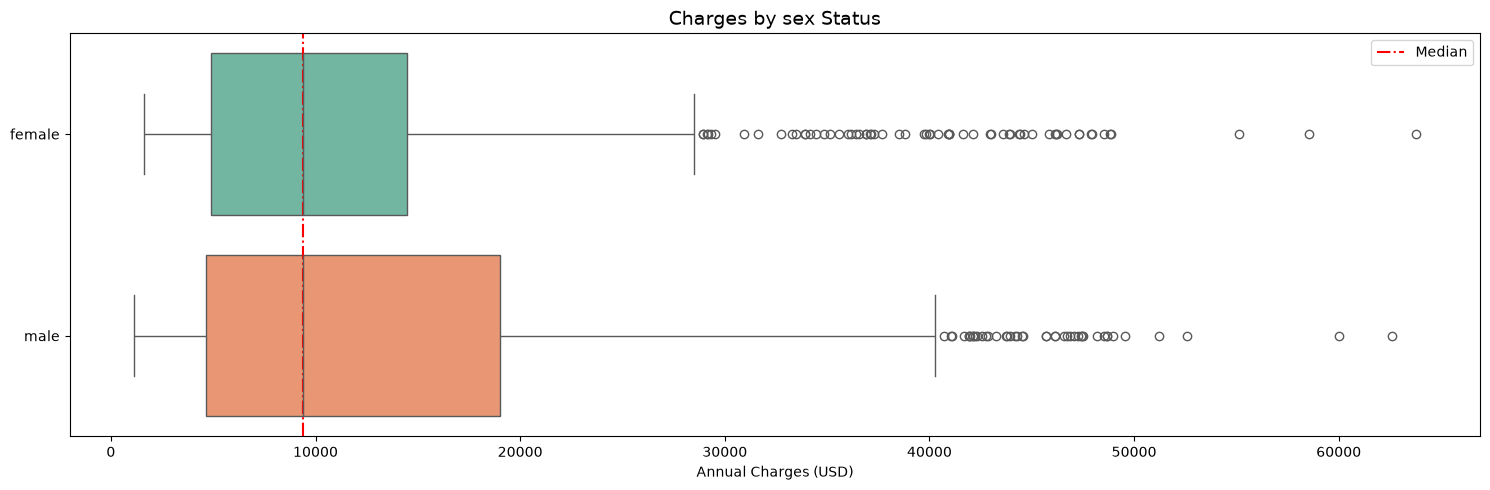

In [18]:
plt.figure(figsize=(15,5))
sns.boxplot(data=df, x='charges', y='sex', palette='Set2')
plt.axvline(df['charges'].median(), color='red', linestyle='-.', label='Median')
plt.title('Charges by sex Status', fontsize=14)
plt.xlabel('Annual Charges (USD)')
plt.legend()
plt.ylabel('')
plt.tight_layout()
plt.show()

C:\Users\abdel\AppData\Local\Temp\ipykernel_7696\1677689042.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='charges', y='sex', inner='quartile', palette='Set2')


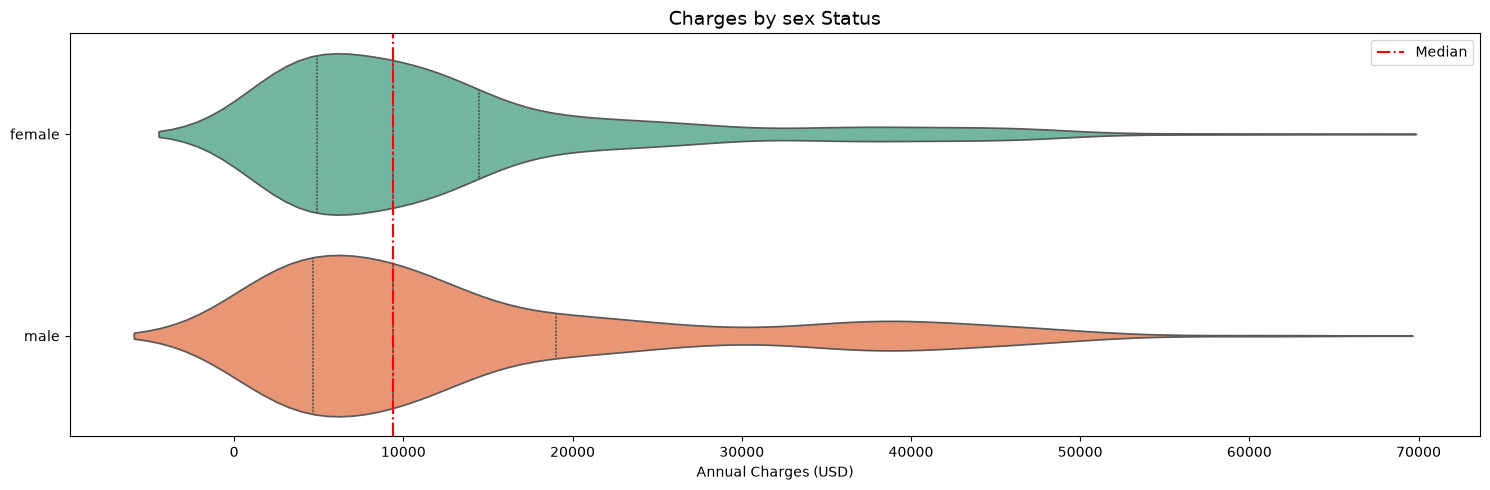

In [19]:
plt.figure(figsize=(15,5))
sns.violinplot(data=df, x='charges', y='sex', inner='quartile', palette='Set2')
plt.axvline(df['charges'].median(), color='red', linestyle='-.', label='Median')
plt.title('Charges by sex Status', fontsize=14)
plt.xlabel('Annual Charges (USD)')
plt.legend()
plt.ylabel('')
plt.tight_layout()

- So ``Sex`` has **almost no effect** on ``charges``. 
- **Median** ``charges`` are **similar** for **males** and **females**, but **charges** vary more among **males**.
- ``Sex`` alone **does not appear to strongl**y predict typical ``charges``.

#### Charges by smoker Status

In [20]:
smoker_summary = df.groupby('smoker')['charges'].agg(
    count='count',
    mean='mean',
    median='median'
)

display(smoker_summary)

ratio = smoker_summary.loc['yes', 'mean'] / smoker_summary.loc['no', 'mean']
print(f"'Smokers' average charges are {ratio:.1f} times those of non-smokers.")

,count,mean,median
smoker,,,
no,1063,8440.660307,7345.72660
yes,274,32050.231832,34456.34845


'Smokers' average charges are 3.8 times those of non-smokers.


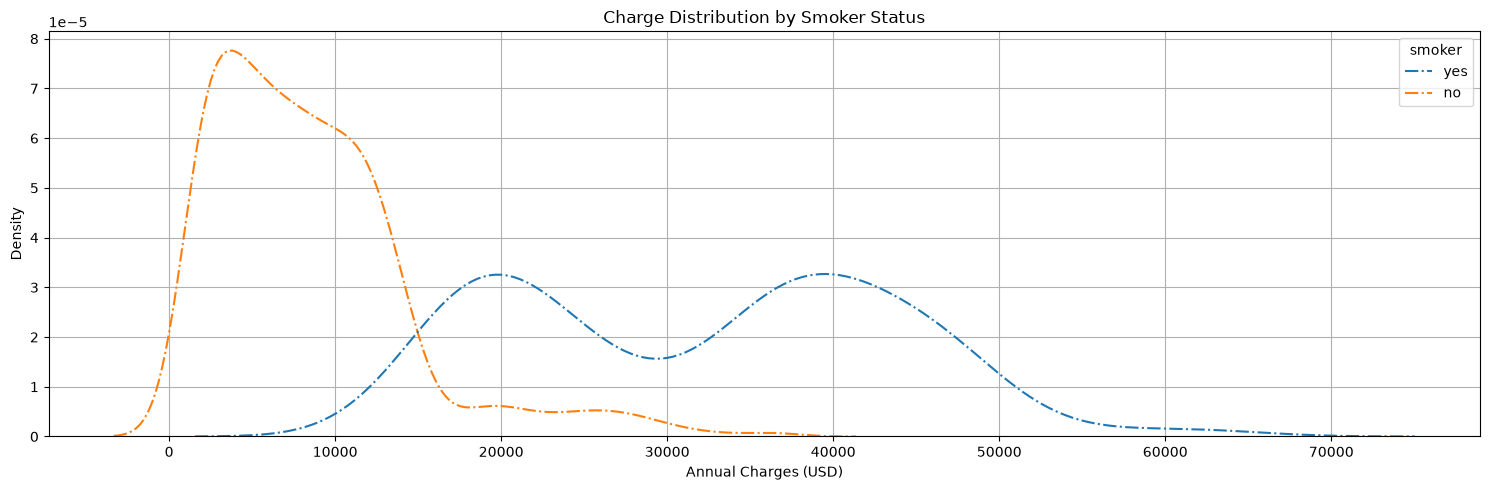

In [21]:
plt.figure(figsize=(15, 5))
sns.kdeplot(data=df, x='charges', hue='smoker', linestyle='-.', common_norm=False)
plt.title('Charge Distribution by Smoker Status')
plt.xlabel('Annual Charges (USD)')
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\abdel\AppData\Local\Temp\ipykernel_7696\3715660730.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='charges', y='smoker', palette='Set2')


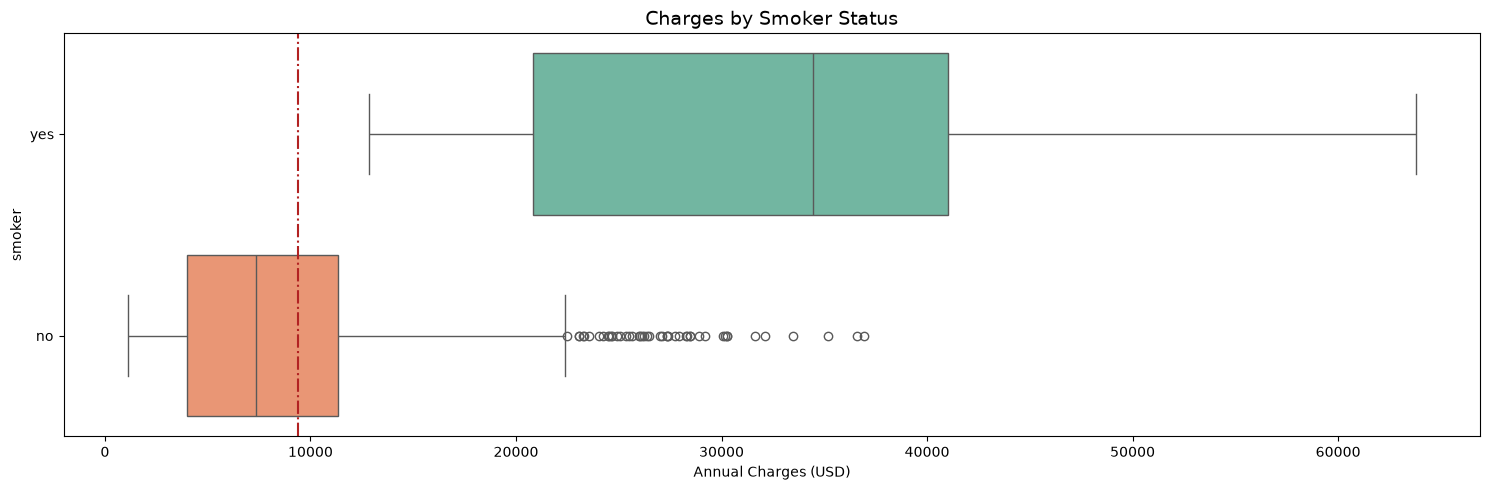

In [22]:
plt.figure(figsize=(15,5))
sns.boxplot(data=df, x='charges', y='smoker', palette='Set2')
plt.axvline(df['charges'].median(), color='firebrick', linestyle='-.', label='Median')
plt.title('Charges by Smoker Status', fontsize=14)
plt.xlabel('Annual Charges (USD)')
plt.tight_layout()

C:\Users\abdel\AppData\Local\Temp\ipykernel_7696\1467273850.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='charges', y='smoker', palette='Set2', inner='quartile')


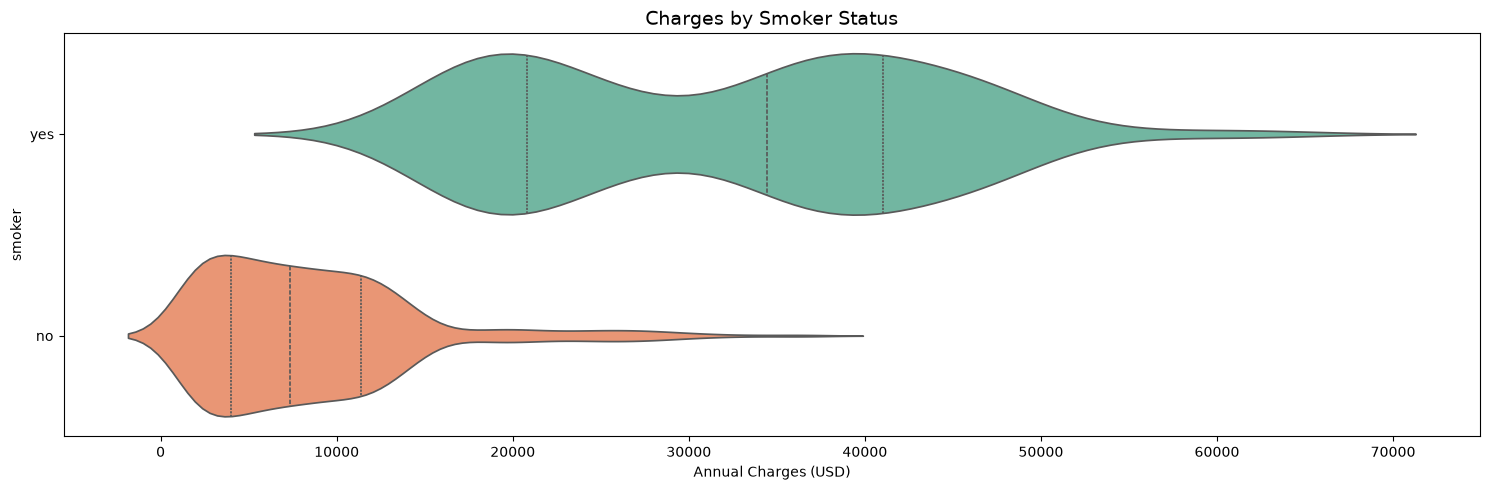

In [23]:
plt.figure(figsize=(15, 5))
sns.violinplot(data=df, x='charges', y='smoker', palette='Set2', inner='quartile')
plt.title('Charges by Smoker Status', fontsize=14)
plt.xlabel('Annual Charges (USD)')
plt.tight_layout()
plt.show()

- **Smokers** have much ``higher insurance charges`` than **non-smokers**.
- This suggests a **strong association between smoking and charges**, but does not prove **smoking** is the **only cause**.

#### charges by N° of Children

In [24]:
display(df.groupby('children')['charges'].agg(
    count='count',
    mean='mean',
    median='median'
))

,count,mean,median
children,,,
0,573,12384.695344,9863.47180
1,324,12731.171832,8483.87015
2,240,15073.563734,9264.97915
3,157,15355.318367,10600.54830
4,25,13850.656311,11033.66170
5,18,8786.035247,8589.56505


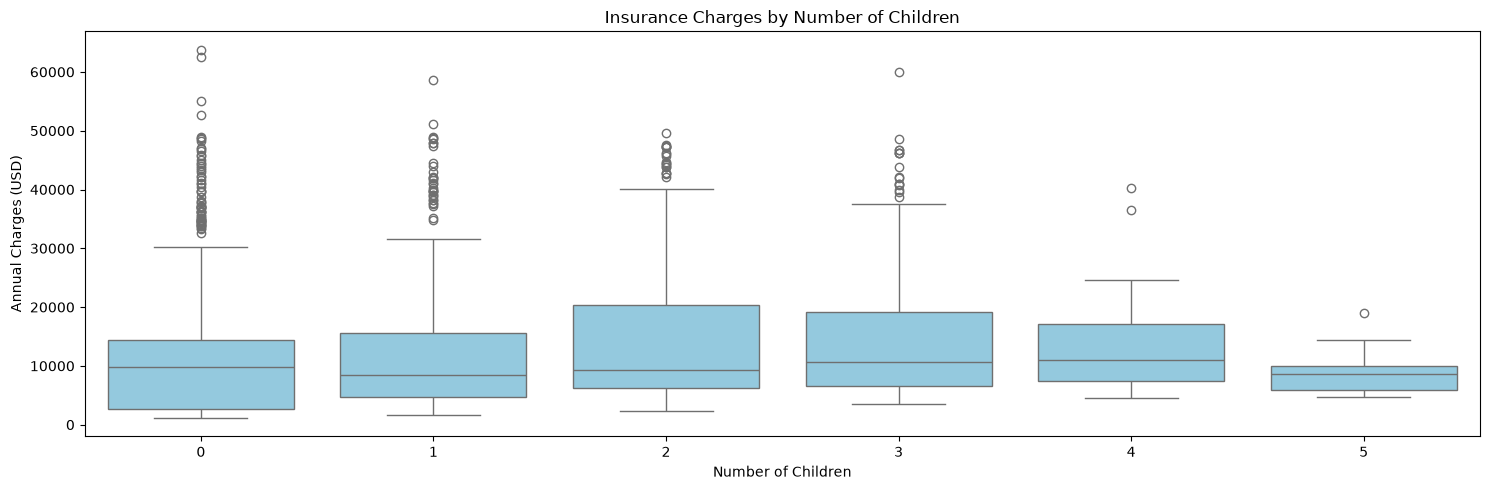

In [25]:
plt.figure(figsize=(15, 5))
sns.boxplot(data=df, x='children', y='charges', color='skyblue')
plt.title('Insurance Charges by Number of Children')
plt.xlabel('Number of Children')
plt.ylabel('Annual Charges (USD)')
plt.tight_layout()
plt.show()

- Charges show no clear pattern by number of children. Groups with 4 or 5 children have fewer records, so interpret those results cautiously.

#### Charges by region Status

C:\Users\abdel\AppData\Local\Temp\ipykernel_7696\2835722909.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='charges', y='region', palette='Set2')


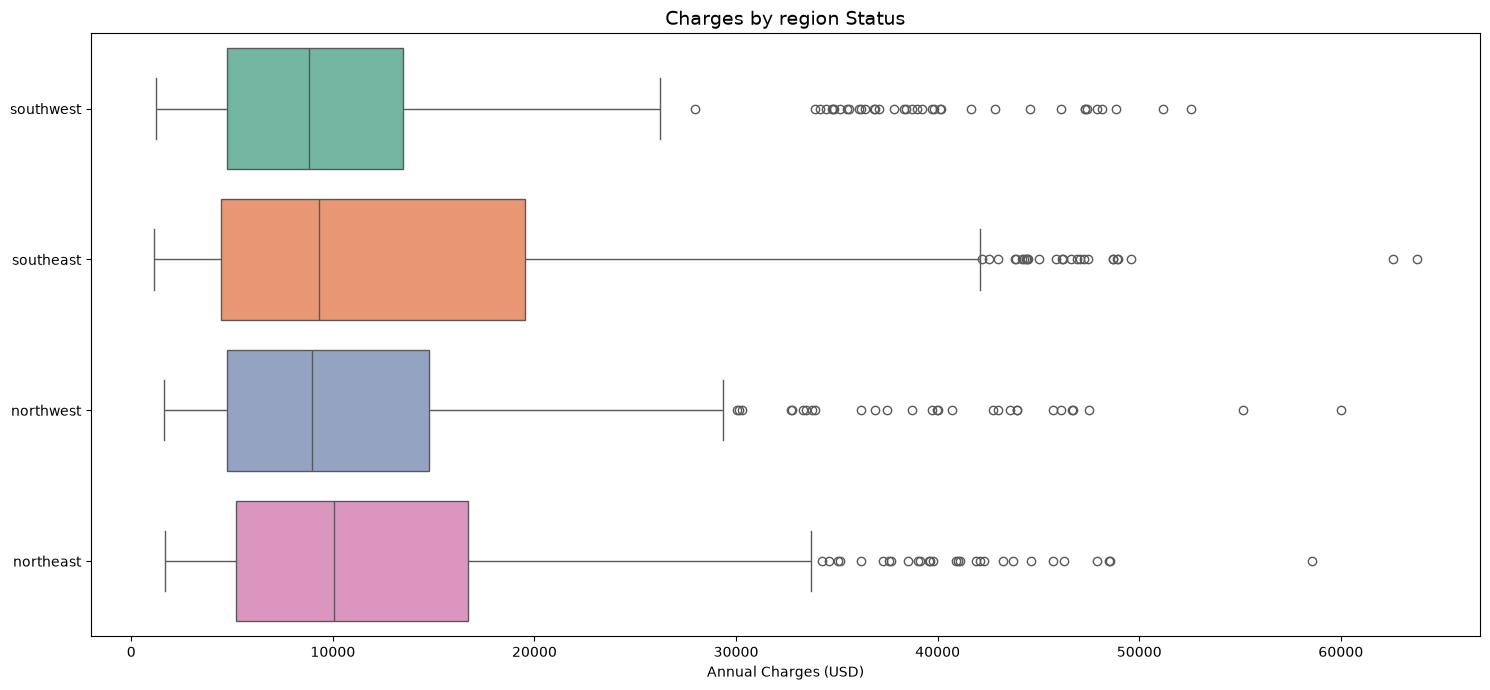

In [26]:
plt.figure(figsize=(15,7))
sns.boxplot(data=df, x='charges', y='region', palette='Set2')
plt.title('Charges by region Status', fontsize=14)
plt.xlabel('Annual Charges (USD)')
plt.ylabel('')
plt.tight_layout()

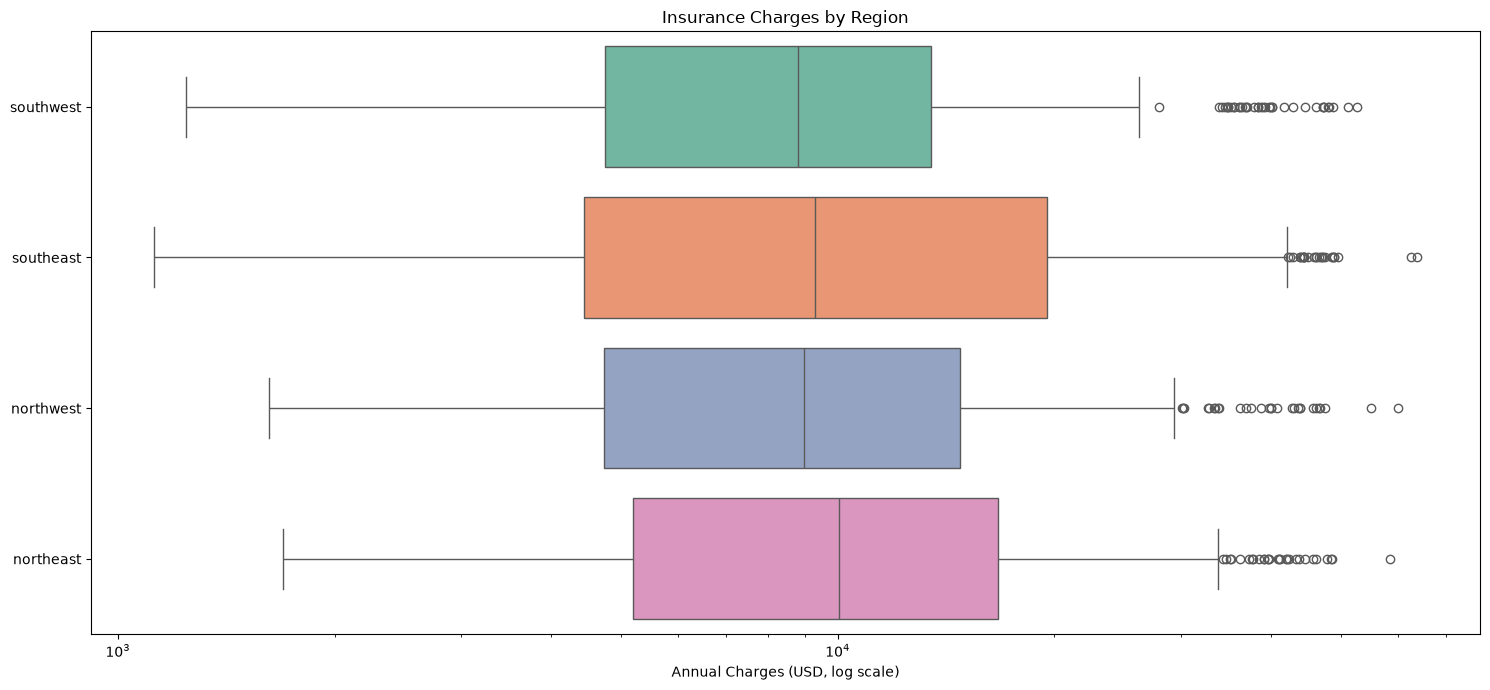

In [27]:
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x='charges', y='region', hue='region', palette='Set2', legend=False)
plt.xscale('log')
plt.title('Insurance Charges by Region')
plt.xlabel('Annual Charges (USD, log scale)')
plt.ylabel('')
plt.tight_layout()
plt.show()

- Median charges are broadly similar across regions, The Southeast shows a wider spread, with some higher-cost cases.

### Some Extra Statistics

#### BMI and charges by smoker status

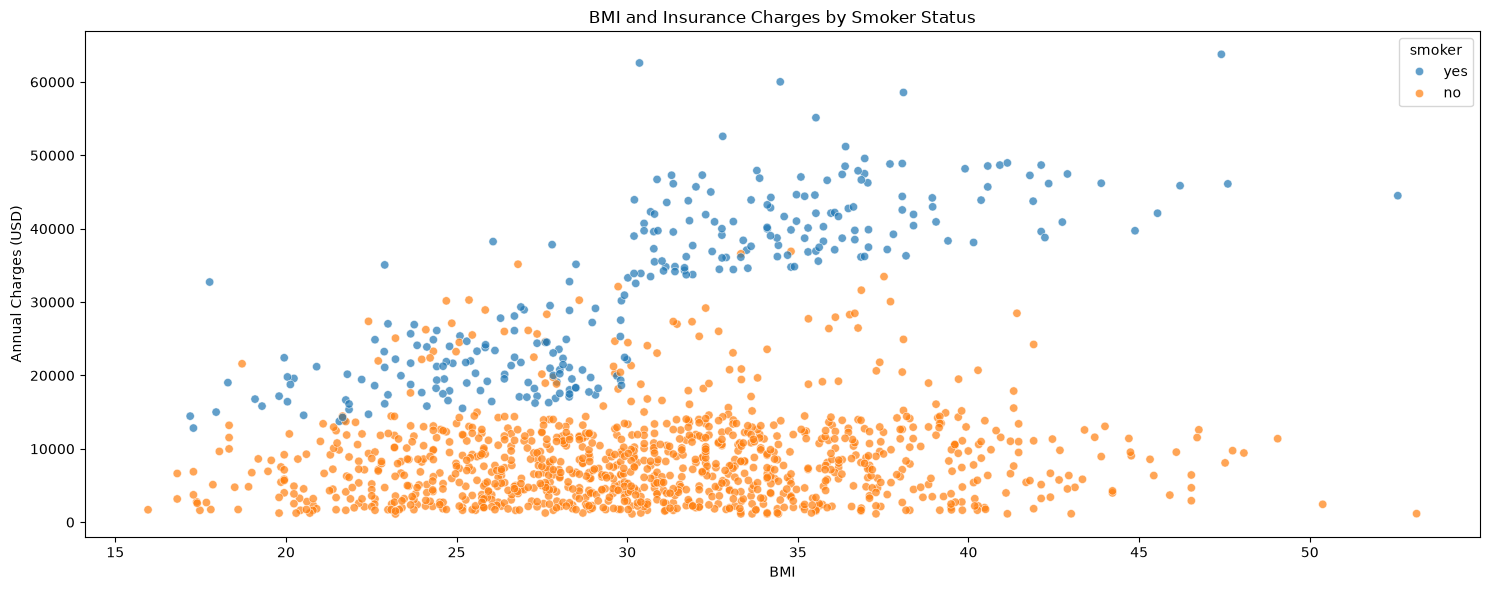

In [28]:
plt.figure(figsize=(15, 6))
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7)
plt.title('BMI and Insurance Charges by Smoker Status')
plt.xlabel('BMI')
plt.ylabel('Annual Charges (USD)')
plt.tight_layout()
plt.show()

- ``Smokers`` generally have **higher charges**.
- ``Charges`` also appear to rise with ``BMI`` more clearly among ``smokers`` than ``non-smokers``.
- The plot shows an association, not proof of cause and effect.

In [29]:
df['bmi_group'] = np.where(df['bmi'] < 30, 'BMI < 30', 'BMI >= 30')

display(df.groupby(['smoker', 'bmi_group'])['charges'].agg(
    count='count',
    mean='mean',
    median='median'
))


count          mean       median
smoker bmi_group                                  
no     BMI < 30     502   7977.029520   6761.61525
       BMI >= 30    561   8855.531349   8083.91980
yes    BMI < 30     129  21363.217016  20167.33603
       BMI >= 30    145  41557.989840  40904.19950

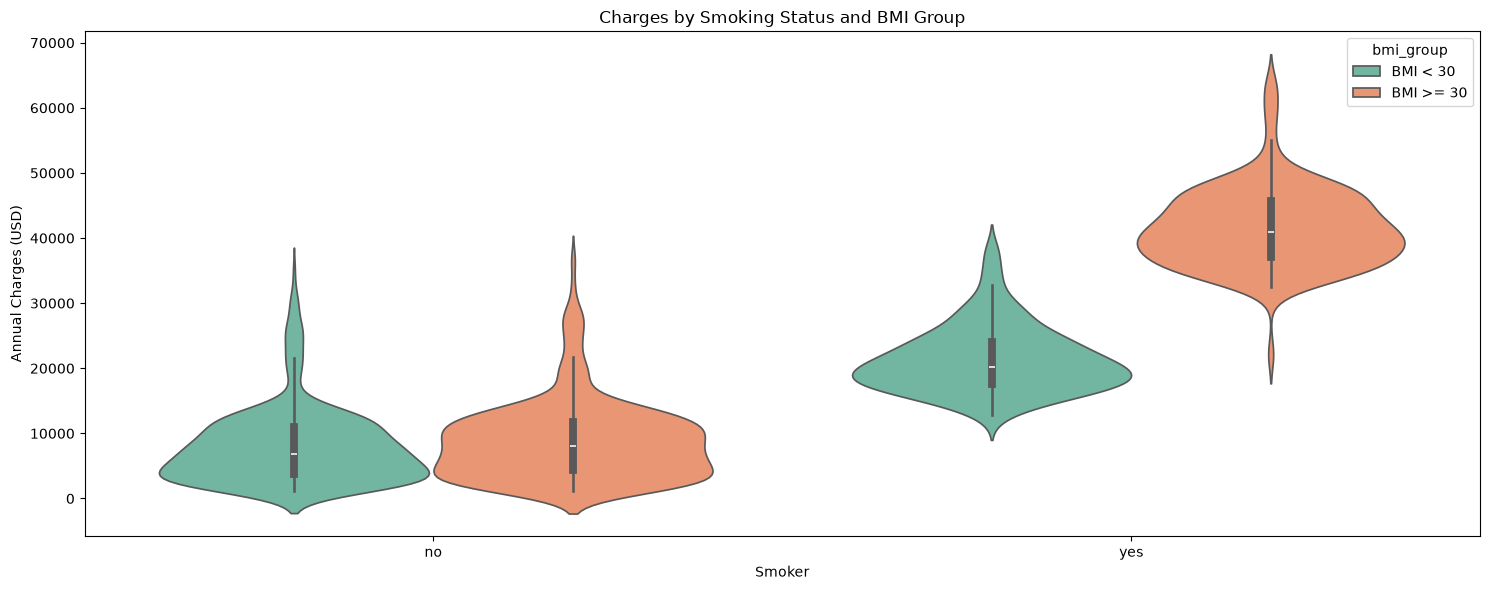

In [30]:

plt.figure(figsize=(15, 6))
sns.violinplot( data=df, x='smoker', y='charges', hue='bmi_group', order=['no', 'yes'], hue_order=['BMI < 30', 'BMI >= 30'], palette='Set2' )
plt.title('Charges by Smoking Status and BMI Group')
plt.xlabel('Smoker')
plt.ylabel('Annual Charges (USD)')
plt.tight_layout()
plt.show()

- Among **non-smokers**, charges look similar across the two **BMI** groups. Among smokers, the **BMI 30+** group has higher charges.
- This shows an association, not cause and effect.

#### age vs charges by smoker status

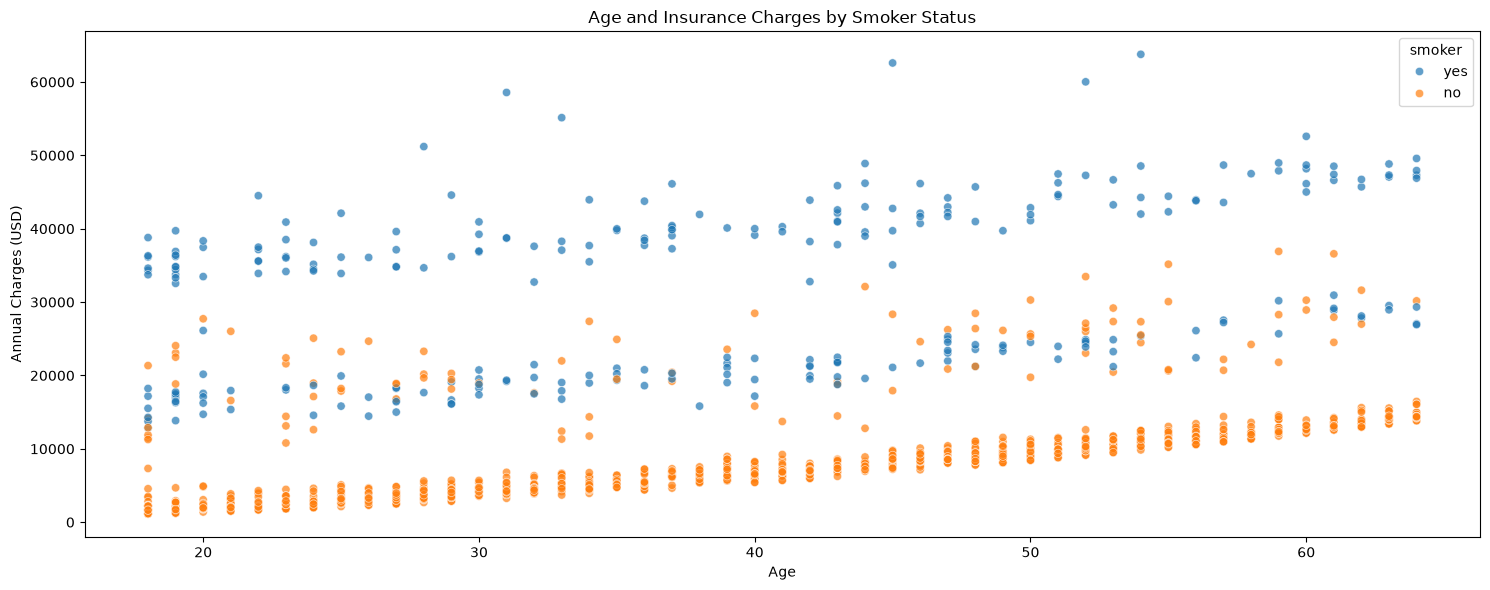

In [31]:
plt.figure(figsize=(15, 6))
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7)
plt.title('Age and Insurance Charges by Smoker Status')
plt.xlabel('Age')
plt.ylabel('Annual Charges (USD)')
plt.tight_layout()
plt.show()

- ``Charges`` generally **rise** with ``age``, and ``smokers`` tend to have **higher charges** across ``age`` groups.

In [32]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[18, 30, 40, 50, 65],
    labels=['18-29', '30-39', '40-49', '50-64'],
    right=False
)

display(df.groupby(['age_group', 'smoker'], observed=True)['charges'].agg(
    count='count',
    mean='mean',
    median='median'
))

count          mean        median
age_group smoker                                   
18-29     no        330   4426.989502   2709.177925
          yes        86  27518.035262  33604.251925
30-39     no        199   6337.362945   5400.980500
          yes        58  30271.246415  34112.913150
40-49     no        217   9183.342097   8240.589600
          yes        62  32654.718697  36449.549360
50-64     no        317  13430.898767  12029.286700
          yes        68  38748.347618  43696.402750

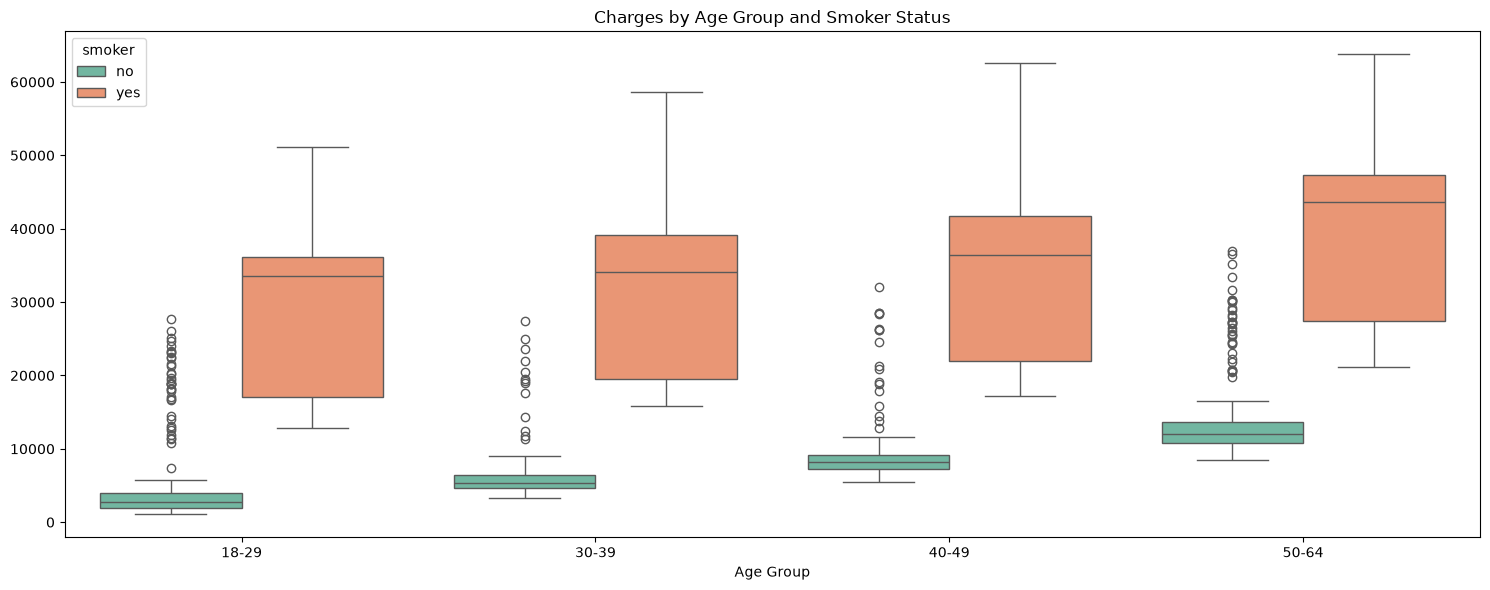

In [33]:
plt.figure(figsize=(15, 6))
sns.boxplot(
    data=df, x='age_group', y='charges',
    hue='smoker', hue_order=['no', 'yes'], palette='Set2'
)
plt.title('Charges by Age Group and Smoker Status')
plt.xlabel('Age Group')
plt.ylabel('')
plt.tight_layout()
plt.show()

- **Median charges** rise across age groups for both **smokers** and **non-smokers**.
- **Smokers** have much **higher charges** in every **age group**.

#### Sex vs charges by smoker status

In [34]:
display(df.groupby('sex')['charges'].agg(
    count='count',
    mean='mean',
    median='median'
))

,count,mean,median
sex,,,
female,662,12569.578844,9412.9625
male,675,13974.998864,9377.9047


In [35]:
display((pd.crosstab(df['sex'], df['smoker'], normalize='index') * 100).round(1))

smoker,no,yes
sex,,
female,82.6,17.4
male,76.4,23.6


- Average ``charges`` were about **``$1,405``** higher for **males**, but the **median charges** were almost the same (about $**``9,400``**).
- ``Smoking`` was more common among **males** **``(23.6% vs. 17.4%)``**, which may partly explain the difference in averages.

In [36]:
display(df.groupby(['sex', 'smoker'])['charges'].agg(
    count='count',
    mean='mean',
    median='median'
).round(2))

count      mean    median
sex    smoker                           
female no        547   8762.30   7639.42
       yes       115  30679.00  28950.47
male   no        516   8099.70   6986.10
       yes       159  33042.01  36085.22

- Men have higher average charges among smokers, but lower charges among non smokers, The overall difference isn’t due to sex alone.


### Statistical Tests

In [37]:
from scipy.stats import mannwhitneyu, kruskal

In [38]:
smoker_p = mannwhitneyu(
    df.loc[df['smoker'] == 'yes', 'charges'],
    df.loc[df['smoker'] == 'no', 'charges']
).pvalue

print(f"Smoker p-value: {smoker_p:.3g}")

Smoker p-value: 5.75e-130


- **Charges** differ **significantly** by **smoking status** (p < 0.001).


In [39]:
sex_p = mannwhitneyu(
    df.loc[df['sex'] == 'male', 'charges'],
    df.loc[df['sex'] == 'female', 'charges']
).pvalue
print(f"Sex p-value: {sex_p:.3g}")

Sex p-value: 0.694


In [40]:
region_groups = [g['charges'] for _, g in df.groupby('region')]
region_p = kruskal(*region_groups).pvalue

print(f"Region p-value: {region_p:.3g}")

Region p-value: 0.202


- The **tests** found no **statistically significant** differences by **sex** (p = 0.694) or **region** (p = 0.202).
- This does not prove that **sex** or **region** has no effect.

## Final Summary

- Smoking had the clearest association with charges. Average charges were about $32,050 for smokers and $8,441 for non-smokers.
- Charges generally increased with age. The BMI pattern was more noticeable among smokers.
- The tests found no significant difference by sex or region. Charges showed no clear pattern by number of children.

## Limitations

This analysis used 1,337 records from one snapshot and did not include health-history information. The results show associations, not causes.